# Implementasi & Evaluasi Metode K-Nearest Neighbor (KNN)

Notebook ini mengimplementasikan **Subbab 3.11 (Implementasi K-Nearest Neighbor)** dan **Subbab 3.12 (Evaluasi Kinerja Model)** pada proposal skripsi.

### Alur Proses pada Notebook Ini:
1. **Memuat Data Latih & Data Uji Hasil TF-IDF** (`tfidf_split_data.pkl`) agar kondisi eksperimen 100% setara dengan Multinomial Naive Bayes.
2. **Memahami Cara Kerja KNN & Cosine Similarity** melalui simulasi pencarian tetangga terdekat pada 1 ulasan uji.
3. **Eksperimen Variasi Nilai $K = 3, 5, 7, 9, \text{dan } 11$** menggunakan ukuran kemiripan **Cosine Similarity** (`metric='cosine'`).
4. **Menentukan Nilai $K$ Terbaik** dan memvisualisasikan grafik pengaruh perubahan nilai $K$ terhadap *Accuracy*, *Precision*, *Recall*, dan *F1-Score*.
5. **Evaluasi Detail Model KNN Terbaik** menggunakan **Confusion Matrix (TP, TN, FP, FN)** dan laporan klasifikasi.
6. **Menyimpan Model & Hasil Evaluasi KNN** ke folder `../data/model-knn/` untuk dibandingkan dengan Multinomial Naive Bayes.

---
## 1. Import Library & Memuat Data Hasil Pembagian dan TF-IDF

In [1]:
import os
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Memuat paket data hasil split (80:20) dan pembobotan TF-IDF yang sama dengan Naive Bayes
paket_data = joblib.load("../data/tfidf_split_data.pkl")

X_train_tfidf = paket_data['X_train_tfidf']
X_test_tfidf = paket_data['X_test_tfidf']
y_train = paket_data['y_train']
y_test = paket_data['y_test']
X_train_text = paket_data['X_train_text']
X_test_text = paket_data['X_test_text']

print("=== DATA SIAP DIGUNAKAN UNTUK K-NEAREST NEIGHBOR (KNN) ===")
print(f"Bentuk Matriks Latih (X_train_tfidf) : {X_train_tfidf.shape[0]} dokumen x {X_train_tfidf.shape[1]} fitur")
print(f"Bentuk Matriks Uji   (X_test_tfidf)  : {X_test_tfidf.shape[0]} dokumen x {X_test_tfidf.shape[1]} fitur")
print(f"Distribusi Label Latih (y_train)     : Positif = {(y_train == 'positif').sum()}, Negatif = {(y_train == 'negatif').sum()}")
print(f"Distribusi Label Uji   (y_test)      : Positif = {(y_test == 'positif').sum()}, Negatif = {(y_test == 'negatif').sum()}")

=== DATA SIAP DIGUNAKAN UNTUK K-NEAREST NEIGHBOR (KNN) ===
Bentuk Matriks Latih (X_train_tfidf) : 8585 dokumen x 57901 fitur
Bentuk Matriks Uji   (X_test_tfidf)  : 2147 dokumen x 57901 fitur
Distribusi Label Latih (y_train)     : Positif = 4512, Negatif = 4073
Distribusi Label Uji   (y_test)      : Positif = 1128, Negatif = 1019


---
## 2. Konsep Cara Kerja KNN & Pengukuran Kemiripan Cosine Similarity

**Sesuai Subbab 3.11.1 Proposal Skripsi:**
Berbeda dengan Naive Bayes yang menghitung probabilitas kata, **K-Nearest Neighbor (KNN)** adalah metode *Instance-Based Learning* (*Lazy Learner*). Saat proses `.fit()`, KNN hanya menyimpan vektor TF-IDF Data Latih di memori.

Ketika ada ulasan dari **Data Uji ($A$)** yang ingin diprediksi, KNN melakukan langkah berikut:
1. Menghitung tingkat kemiripan vektor ulasan uji ($A$) terhadap seluruh vektor ulasan di Data Latih ($B$) menggunakan **Cosine Similarity**:
   $$\text{Cosine Similarity}(A, B) = \frac{A \cdot B}{\|A\| \|B\|}$$
   - Nilai mendekati **$1$** artinya kedua ulasan memiliki kata/frasa yang **sangat mirip**.
   - Nilai **$0$** artinya kedua ulasan tidak memiliki kata yang sama.
   - *(Catatan Teknis Scikit-Learn: Parameter `metric='cosine'` pada `KNeighborsClassifier` menghitung **Cosine Distance** $= 1 - \text{Cosine Similarity}$. Semakin kecil jaraknya [mendekati 0], maka nilai Cosine Similarity-nya semakin besar [mendekati 1]).*
2. Mengambil sejumlah **$K$ ulasan Data Latih** yang memiliki nilai *Cosine Similarity* tertinggi (tetangga terdekat).
3. Melakukan **Voting Mayoritas**: Kelas sentimen yang paling banyak dimiliki oleh $K$ tetangga tersebut ditetapkan sebagai hasil prediksi!

### Simulasi Nyata Pencarian Tetangga Terdekat pada 1 Sampel Data Uji (Bahan Bab IV Skripsi):

In [2]:
# Membuat model KNN contoh dengan K = 5 dan metrik Cosine untuk melihat cara kerjanya secara nyata
knn_contoh = KNeighborsClassifier(n_neighbors=5, metric='cosine')
knn_contoh.fit(X_train_tfidf, y_train)

# Ambil 1 contoh ulasan dari Data Uji (baris ke-0)
idx_uji_sampel = 0
teks_uji_sampel = X_test_text.iloc[idx_uji_sampel]
label_aktual_sampel = y_test.iloc[idx_uji_sampel]
vektor_uji_sampel = X_test_tfidf[idx_uji_sampel]

# Mencari 5 tetangga terdekat dari Data Latih menggunakan fungsi .kneighbors()
# Fungsi ini mengembalikan jarak cosine (cosine_distance = 1 - cosine_similarity) dan indeks data latihnya
jarak_cosine, indeks_tetangga = knn_contoh.kneighbors(vektor_uji_sampel, n_neighbors=5)

# Mengubah Cosine Distance kembali menjadi Cosine Similarity (Similarity = 1 - Distance)
nilai_similarity = 1.0 - jarak_cosine[0]
idx_latih_terdekat = indeks_tetangga[0]

print(f"Ulasan Data Uji (Sampel #{idx_uji_sampel}) : '{teks_uji_sampel}'")
print(f"Label Aktual Sebenarnya     : {label_aktual_sampel}")
print(f"Hasil Prediksi Voting (K=5) : {knn_contoh.predict(vektor_uji_sampel)[0]}")

# Menampilkan tabel 5 tetangga terdekat dari Data Latih
df_tetangga = pd.DataFrame({
    'Tetangga Ke-': [f"Tetangga #{i+1}" for i in range(5)],
    'Teks Ulasan di Data Latih': X_train_text.iloc[idx_latih_terdekat].values,
    'Cosine Similarity': np.round(nilai_similarity, 4),
    'Cosine Distance': np.round(jarak_cosine[0], 4),
    'Label Sentimen Tetangga': y_train.iloc[idx_latih_terdekat].values
})

print("\nTabel 5 Tetangga Terdekat (Data Latih) Berdasarkan Cosine Similarity:")
df_tetangga

Ulasan Data Uji (Sampel #0) : 'mantap hemat'
Label Aktual Sebenarnya     : positif
Hasil Prediksi Voting (K=5) : positif

Tabel 5 Tetangga Terdekat (Data Latih) Berdasarkan Cosine Similarity:


,Tetangga Ke-,Teks Ulasan di Data Latih,Cosine Similarity,Cosine Distance,Label Sentimen Tetangga
0,Tetangga #1,mantap,0.6741,0.3259,positif
1,Tetangga #2,mantap,0.6741,0.3259,positif
2,Tetangga #3,mantap,0.6741,0.3259,positif
3,Tetangga #4,mantap,0.6741,0.3259,positif
4,Tetangga #5,mantap,0.6741,0.3259,positif


---
## 3. Pengujian KNN dengan Variasi Nilai $K = 3, 5, 7, 9, \text{dan } 11$

**Sesuai Subbab 3.11.2 & 3.11.3 Proposal Skripsi:**
- Kita menguji 5 variasi nilai $K$ ganjil, yaitu **$K = 3, 5, 7, 9, \text{dan } 11$**.
- **Mengapa nilai $K$ harus ganjil?** Karena penelitian ini menggunakan 2 kelas sentimen (`positif` dan `negatif`). Dengan jumlah tetangga $K$ yang ganjil, hasil pemungutan suara (*voting*) tidak akan pernah berakhir seri (*tie*).
- Pada kode di bawah, kita melakukan perulangan (*loop*) untuk melatih model KNN pada setiap nilai $K$, memprediksi Data Uji, dan mencatat seluruh metrik evaluasinya (**TP, TN, FP, FN, Accuracy, Precision, Recall, dan F1-Score**).

In [3]:
# Daftar nilai K yang diuji sesuai Bab III Proposal Skripsi
daftar_k = [3, 5, 7, 9, 11]

# Dictionary dan list untuk menyimpan hasil pengujian setiap nilai K
hasil_eksperimen_knn = []
koleksi_model_knn = {}
koleksi_prediksi_knn = {}
koleksi_cm_knn = {}

print("Memulai proses pengujian KNN untuk K = 3, 5, 7, 9, 11 ...\n")

for k in daftar_k:
    # 1. Inisialisasi model KNN dengan nilai K saat ini dan metrik Cosine
    model_knn = KNeighborsClassifier(n_neighbors=k, metric='cosine', n_jobs=-1)
    
    # 2. Latih model dengan Data Latih TF-IDF
    model_knn.fit(X_train_tfidf, y_train)
    
    # 3. Lakukan prediksi pada Data Uji TF-IDF
    y_pred_k = model_knn.predict(X_test_tfidf)
    
    # 4. Hitung Confusion Matrix (urutan label ['positif', 'negatif'] sesuai Tabel 3.5 Proposal)
    cm_k = confusion_matrix(y_test, y_pred_k, labels=['positif', 'negatif'])
    tp_k, fn_k = cm_k[0, 0], cm_k[0, 1]
    fp_k, tn_k = cm_k[1, 0], cm_k[1, 1]
    
    # 5. Hitung Accuracy, Precision, Recall, dan F1-Score
    acc_k = accuracy_score(y_test, y_pred_k)
    prec_k = precision_score(y_test, y_pred_k, pos_label='positif')
    rec_k = recall_score(y_test, y_pred_k, pos_label='positif')
    f1_k = f1_score(y_test, y_pred_k, pos_label='positif')
    
    # Simpan ke dalam koleksi
    koleksi_model_knn[k] = model_knn
    koleksi_prediksi_knn[k] = y_pred_k
    koleksi_cm_knn[k] = cm_k
    
    hasil_eksperimen_knn.append({
        'Nilai K': k,
        'Metode': f'KNN (K={k})',
        'Accuracy': acc_k,
        'Precision': prec_k,
        'Recall': rec_k,
        'F1-Score': f1_k,
        'Accuracy (%)': round(acc_k * 100, 2),
        'Precision (%)': round(prec_k * 100, 2),
        'Recall (%)': round(rec_k * 100, 2),
        'F1-Score (%)': round(f1_k * 100, 2),
        'TP': int(tp_k),
        'TN': int(tn_k),
        'FP': int(fp_k),
        'FN': int(fn_k)
    })
    
    print(f"[Selesai] K = {k:2d} -> Accuracy: {acc_k*100:.2f}% | Precision: {prec_k*100:.2f}% | Recall: {rec_k*100:.2f}% | F1-Score: {f1_k*100:.2f}%")

# Menampilkan Tabel Perbandingan Seluruh Variasi Nilai K (Siap disalin ke Bab IV Skripsi)
df_perbandingan_k = pd.DataFrame(hasil_eksperimen_knn)
kolom_tampil = ['Nilai K', 'Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'TP', 'TN', 'FP', 'FN']
print("\n=== TABEL HASIL PENGUJIAN KNN PADA BERBAGAI NILAI K (K = 3, 5, 7, 9, 11) ===")
df_perbandingan_k[kolom_tampil]

Memulai proses pengujian KNN untuk K = 3, 5, 7, 9, 11 ...

[Selesai] K =  3 -> Accuracy: 84.54% | Precision: 81.94% | Recall: 90.51% | F1-Score: 86.02%
[Selesai] K =  5 -> Accuracy: 85.42% | Precision: 83.05% | Recall: 90.78% | F1-Score: 86.74%
[Selesai] K =  7 -> Accuracy: 85.84% | Precision: 83.44% | Recall: 91.13% | F1-Score: 87.12%
[Selesai] K =  9 -> Accuracy: 86.45% | Precision: 84.28% | Recall: 91.22% | F1-Score: 87.61%
[Selesai] K = 11 -> Accuracy: 87.28% | Precision: 85.65% | Recall: 91.05% | F1-Score: 88.27%

=== TABEL HASIL PENGUJIAN KNN PADA BERBAGAI NILAI K (K = 3, 5, 7, 9, 11) ===


,Nilai K,Accuracy (%),Precision (%),Recall (%),F1-Score (%),TP,TN,FP,FN
0,3,84.54,81.94,90.51,86.02,1021,794,225,107
1,5,85.42,83.05,90.78,86.74,1024,810,209,104
2,7,85.84,83.44,91.13,87.12,1028,815,204,100
3,9,86.45,84.28,91.22,87.61,1029,827,192,99
4,11,87.28,85.65,91.05,88.27,1027,847,172,101


---
## 4. Penentuan Nilai $K$ Terbaik & Visualisasi Pengaruh Nilai $K$

**Sesuai Subbab 3.12.6 & 3.13 Proposal Skripsi:**
Dari kelima variasi nilai $K$ ($3, 5, 7, 9, 11$), kita menentukan **konfigurasi nilai $K$ terbaik** berdasarkan nilai **F1-Score** dan **Accuracy** tertinggi. Nilai $K$ terbaik inilah yang nantinya akan mewakili metode K-Nearest Neighbor untuk dibandingkan dengan metode Multinomial Naive Bayes.

=== PENENTUAN NILAI K TERBAIK PADA METODE KNN ===
Nilai K Terbaik  : K = 11
- Accuracy       : 87.28%
- Precision      : 85.65%
- Recall         : 91.05%
- F1-Score       : 88.27%


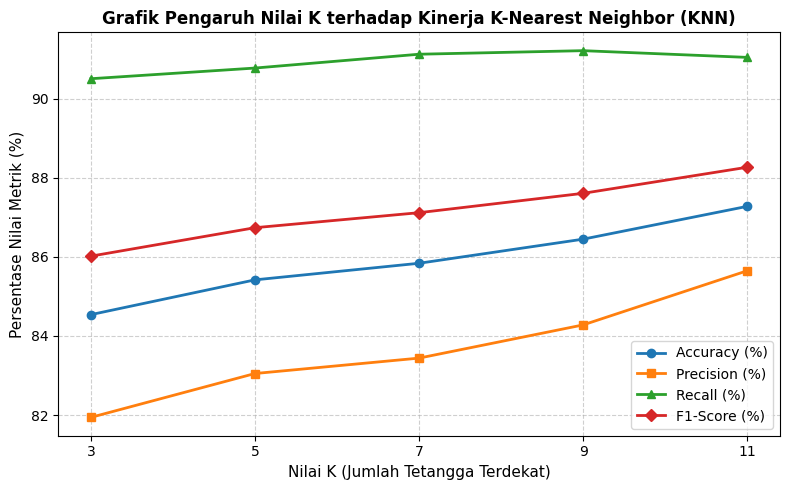

In [4]:
# Mengurutkan berdasarkan F1-Score dan Accuracy tertinggi untuk mencari K terbaik
baris_terbaik = df_perbandingan_k.sort_values(by=['F1-Score', 'Accuracy'], ascending=False).iloc[0]
k_terbaik = int(baris_terbaik['Nilai K'])

print("=== PENENTUAN NILAI K TERBAIK PADA METODE KNN ===")
print(f"Nilai K Terbaik  : K = {k_terbaik}")
print(f"- Accuracy       : {baris_terbaik['Accuracy (%)']:.2f}%")
print(f"- Precision      : {baris_terbaik['Precision (%)']:.2f}%")
print(f"- Recall         : {baris_terbaik['Recall (%)']:.2f}%")
print(f"- F1-Score       : {baris_terbaik['F1-Score (%)']:.2f}%")

# Visualisasi Grafik Garis (Line Chart) Pengaruh Nilai K terhadap Kinerja KNN
plt.figure(figsize=(8, 5))
plt.plot(df_perbandingan_k['Nilai K'], df_perbandingan_k['Accuracy (%)'], marker='o', linewidth=2, label='Accuracy (%)')
plt.plot(df_perbandingan_k['Nilai K'], df_perbandingan_k['Precision (%)'], marker='s', linewidth=2, label='Precision (%)')
plt.plot(df_perbandingan_k['Nilai K'], df_perbandingan_k['Recall (%)'], marker='^', linewidth=2, label='Recall (%)')
plt.plot(df_perbandingan_k['Nilai K'], df_perbandingan_k['F1-Score (%)'], marker='D', linewidth=2, label='F1-Score (%)')

plt.title('Grafik Pengaruh Nilai K terhadap Kinerja K-Nearest Neighbor (KNN)', fontsize=12, fontweight='bold')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=11)
plt.ylabel('Persentase Nilai Metrik (%)', fontsize=11)
plt.xticks(daftar_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

---
## 5. Evaluasi Detail Model KNN pada Nilai $K$ Terbaik

Bagian ini menampilkan **Confusion Matrix (TP, TN, FP, FN)** beserta visualisasi *Heatmap* dan laporan klasifikasi lengkap untuk model **KNN Terbaik ($K = K_{\text{terbaik}}$)**.

=== RINCIAN CONFUSION MATRIX KNN TERBAIK (K = 11) ===
- True Positive  (TP) : 1027 (Aktual Positif -> Prediksi Positif)
- True Negative  (TN) : 847 (Aktual Negatif -> Prediksi Negatif)
- False Positive (FP) : 172 (Aktual Negatif -> Prediksi Positif)
- False Negative (FN) : 101 (Aktual Positif -> Prediksi Negatif)


,Prediksi: Positif,Prediksi: Negatif
Aktual: Positif,1027,101
Aktual: Negatif,172,847


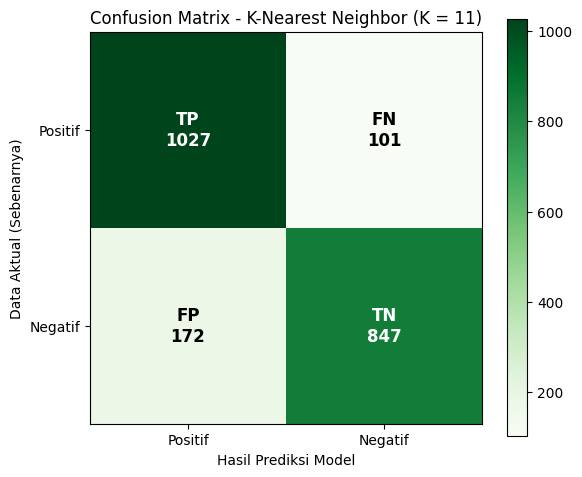


=== LAPORAN KLASIFIKASI LENGKAP KNN TERBAIK (K = 11) ===
              precision    recall  f1-score   support

     negatif     0.8935    0.8312    0.8612      1019
     positif     0.8565    0.9105    0.8827      1128

    accuracy                         0.8728      2147
   macro avg     0.8750    0.8708    0.8719      2147
weighted avg     0.8741    0.8728    0.8725      2147



In [5]:
# Mengambil model, hasil prediksi, dan confusion matrix dari K Terbaik
model_knn_terbaik = koleksi_model_knn[k_terbaik]
y_pred_knn_terbaik = koleksi_prediksi_knn[k_terbaik]
cm_knn_terbaik = koleksi_cm_knn[k_terbaik]

TP_knn = cm_knn_terbaik[0, 0]
FN_knn = cm_knn_terbaik[0, 1]
FP_knn = cm_knn_terbaik[1, 0]
TN_knn = cm_knn_terbaik[1, 1]

print(f"=== RINCIAN CONFUSION MATRIX KNN TERBAIK (K = {k_terbaik}) ===")
print(f"- True Positive  (TP) : {TP_knn} (Aktual Positif -> Prediksi Positif)")
print(f"- True Negative  (TN) : {TN_knn} (Aktual Negatif -> Prediksi Negatif)")
print(f"- False Positive (FP) : {FP_knn} (Aktual Negatif -> Prediksi Positif)")
print(f"- False Negative (FN) : {FN_knn} (Aktual Positif -> Prediksi Negatif)")

# Menampilkan Confusion Matrix dalam bentuk Tabel DataFrame
df_cm_knn = pd.DataFrame(
    cm_knn_terbaik,
    index=['Aktual: Positif', 'Aktual: Negatif'],
    columns=['Prediksi: Positif', 'Prediksi: Negatif']
)
display(df_cm_knn)

# Visualisasi Heatmap Confusion Matrix KNN Terbaik
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_knn_terbaik, interpolation='nearest', cmap=plt.cm.Greens)
ax.figure.colorbar(im, ax=ax)

ax.set(
    xticks=np.arange(cm_knn_terbaik.shape[1]),
    yticks=np.arange(cm_knn_terbaik.shape[0]),
    xticklabels=['Positif', 'Negatif'],
    yticklabels=['Positif', 'Negatif'],
    title=f'Confusion Matrix - K-Nearest Neighbor (K = {k_terbaik})',
    ylabel='Data Aktual (Sebenarnya)',
    xlabel='Hasil Prediksi Model'
)

label_kotak = [['TP', 'FN'], ['FP', 'TN']]
thresh = cm_knn_terbaik.max() / 2.0
for i in range(cm_knn_terbaik.shape[0]):
    for j in range(cm_knn_terbaik.shape[1]):
        ax.text(
            j, i,
            f"{label_kotak[i][j]}\n{cm_knn_terbaik[i, j]}",
            ha="center", va="center",
            color="white" if cm_knn_terbaik[i, j] > thresh else "black",
            fontsize=12, fontweight='bold'
        )

plt.tight_layout()
plt.show()

print(f"\n=== LAPORAN KLASIFIKASI LENGKAP KNN TERBAIK (K = {k_terbaik}) ===")
print(classification_report(y_test, y_pred_knn_terbaik, target_names=['negatif', 'positif'], digits=4))

---
## 6. Menyimpan Model KNN & Hasil Evaluasi

Kita simpan model KNN terbaik beserta seluruh hasil eksperimen nilai $K=3, 5, 7, 9, 11$ ke dalam folder `../data/model-knn/` agar siap digunakan pada notebook tahap akhir (**Perbandingan Kinerja Metode Multinomial Naive Bayes vs KNN**).

In [6]:
# Pastikan folder ../data/model-knn tersedia
folder_knn = "../data/model-knn"
os.makedirs(folder_knn, exist_ok=True)

# 1. Simpan model KNN Terbaik
joblib.dump(model_knn_terbaik, f"{folder_knn}/model_knn_terbaik.pkl")

# 2. Simpan tabel perbandingan variasi K = 3, 5, 7, 9, 11 ke CSV
df_perbandingan_k.to_csv(f"{folder_knn}/perbandingan_variasi_k_knn.csv", index=False)

# 3. Simpan tabel hasil prediksi Data Uji pada K Terbaik ke CSV
df_hasil_uji_knn = pd.DataFrame({
    'Teks_Ulasan_Bersih': X_test_text.values,
    'Label_Aktual': y_test.values,
    f'Prediksi_KNN_K{k_terbaik}': y_pred_knn_terbaik,
    'Status': np.where(y_test.values == y_pred_knn_terbaik, 'Benar', 'Salah')
})
df_hasil_uji_knn.to_csv(f"{folder_knn}/hasil_prediksi_knn_terbaik.csv", index=False)

# 4. Simpan paket evaluasi lengkap KNN untuk dibandingkan dengan Multinomial Naive Bayes
evaluasi_knn = {
    'nama_metode': f'K-Nearest Neighbor (K={k_terbaik})',
    'k_terbaik': k_terbaik,
    'accuracy': float(baris_terbaik['Accuracy']),
    'precision': float(baris_terbaik['Precision']),
    'recall': float(baris_terbaik['Recall']),
    'f1_score': float(baris_terbaik['F1-Score']),
    'confusion_matrix': cm_knn_terbaik,
    'TP': int(TP_knn),
    'TN': int(TN_knn),
    'FP': int(FP_knn),
    'FN': int(FN_knn),
    'y_pred': y_pred_knn_terbaik,
    'tabel_variasi_k': df_perbandingan_k,
    'koleksi_cm_knn': koleksi_cm_knn
}
joblib.dump(evaluasi_knn, f"{folder_knn}/evaluasi_knn.pkl")

print("=== PENYIMPANAN BERHASIL ===")
print(f"1. Model KNN Terbaik (K={k_terbaik})      -> {folder_knn}/model_knn_terbaik.pkl")
print(f"2. Tabel Perbandingan K (CSV)   -> {folder_knn}/perbandingan_variasi_k_knn.csv")
print(f"3. Tabel Hasil Prediksi (CSV)   -> {folder_knn}/hasil_prediksi_knn_terbaik.csv")
print(f"4. Paket Evaluasi Lengkap KNN   -> {folder_knn}/evaluasi_knn.pkl")

=== PENYIMPANAN BERHASIL ===
1. Model KNN Terbaik (K=11)      -> ../data/model-knn/model_knn_terbaik.pkl
2. Tabel Perbandingan K (CSV)   -> ../data/model-knn/perbandingan_variasi_k_knn.csv
3. Tabel Hasil Prediksi (CSV)   -> ../data/model-knn/hasil_prediksi_knn_terbaik.csv
4. Paket Evaluasi Lengkap KNN   -> ../data/model-knn/evaluasi_knn.pkl
